# Notebook 05 — Metabolic Signatures
## GSE136666 substantia nigra — Parkinson vs Control

### Goal
This notebook converts the broad metabolic enrichment results from Notebook 04 into a **compact, transparent and reproducible metabolic signature** suitable for downstream validation in GSE184950.

### Core principle
A gene can be biologically important in two different ways:

1. **DE-supported gene**
   - statistically supported by the formal PyDESeq2 gene-level model.

2. **Pathway-driver gene**
   - repeatedly appears in the leading edge of significant metabolic pathways, even if its individual `padj` is not significant.

These are **not treated as equivalent evidence**. The notebook preserves both labels and only creates a compact signature after quantifying:
- pathway recurrence;
- pathway database recurrence;
- metabolic-theme recurrence;
- direction of pathway enrichment;
- gene-level log2 fold change;
- PyDESeq2 Wald statistic;
- gene-level FDR;
- agreement between gene-level and pathway-level direction.

### Outputs
The notebook produces:
- full candidate table;
- gene × metabolic-theme evidence matrix;
- gene × database evidence matrix;
- priority tiers;
- compact primary signature;
- extended validation signature;
- pathway-level signature;
- plots and reproducibility manifest.

### Important interpretation
This is a **transcriptomic metabolic signature**, not proof of altered metabolic flux or enzyme activity.

In [1]:
# 0. Imports and reproducibility
from pathlib import Path
import json
import re
import sys
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
ALPHA = 0.05
np.random.seed(RANDOM_STATE)

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("pandas:", pd.__version__)
print("numpy:", np.__version__)

Python: 3.13.5
Platform: Linux-6.18.44-x86_64-with-glibc2.41
pandas: 2.2.3
numpy: 2.3.5


In [2]:
# 1. Project directories and input discovery
PROJECT_ROOT = Path.cwd()

SEARCH_ROOTS = [
    PROJECT_ROOT,
    PROJECT_ROOT.parent,
    PROJECT_ROOT / "data",
    PROJECT_ROOT.parent / "data",
    Path("/mnt/data"),
]

RESULTS_DIR = PROJECT_ROOT / "results" / "metabolic_signatures"
FIGURES_DIR = PROJECT_ROOT / "figures" / "metabolic_signatures"
EXPORT_DIR = PROJECT_ROOT / "data" / "processed" / "notebook05"

for d in [RESULTS_DIR, FIGURES_DIR, EXPORT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

def find_file(pattern):
    matches = []
    for root in SEARCH_ROOTS:
        if root.exists():
            matches.extend(root.rglob(pattern))
    matches = sorted(set(p.resolve() for p in matches if p.is_file()))
    return matches[0] if matches else None

GSEA_METABOLIC_FILE = find_file("GSE136666_SN_GSEA_metabolic_FDR_lt_0.05.csv")
LEADING_EDGE_FILE = find_file("GSE136666_SN_metabolic_leading_edge_candidates.csv")
THEME_SUMMARY_FILE = find_file("GSE136666_SN_metabolic_theme_summary.csv")

print("GSEA metabolic:", GSEA_METABOLIC_FILE)
print("Leading-edge candidates:", LEADING_EDGE_FILE)
print("Theme summary:", THEME_SUMMARY_FILE)

assert GSEA_METABOLIC_FILE is not None
assert LEADING_EDGE_FILE is not None
assert THEME_SUMMARY_FILE is not None

GSEA metabolic: /mnt/data/GSE136666_SN_GSEA_metabolic_FDR_lt_0.05.csv
Leading-edge candidates: /mnt/data/GSE136666_SN_metabolic_leading_edge_candidates.csv
Theme summary: /mnt/data/GSE136666_SN_metabolic_theme_summary.csv


In [3]:
# 2. Load Notebook 04 outputs
gsea = pd.read_csv(GSEA_METABOLIC_FILE)
candidates = pd.read_csv(LEADING_EDGE_FILE)
theme_summary = pd.read_csv(THEME_SUMMARY_FILE)

required_gsea = {
    "term", "library_family", "FDR", "NES",
    "leading_edge", "metabolic_themes"
}
required_candidates = {
    "Symbol", "metabolic_pathway_count", "mean_NES",
    "minimum_FDR", "log2FoldChange", "stat", "pvalue", "padj", "baseMean"
}

assert required_gsea.issubset(gsea.columns), (
    f"Missing GSEA columns: {required_gsea - set(gsea.columns)}"
)
assert required_candidates.issubset(candidates.columns), (
    f"Missing candidate columns: {required_candidates - set(candidates.columns)}"
)

print("Significant metabolic pathways:", len(gsea))
print("Leading-edge candidate genes:", len(candidates))
print("Metabolic theme rows:", len(theme_summary))

display(gsea.head())
display(candidates.head())
display(theme_summary)

Significant metabolic pathways: 138
Leading-edge candidate genes: 998
Metabolic theme rows: 13


,name,term,es,nes,nom_p_val,fdr_q_val,fwer_p_val,tag,gene,lead_genes,library_family,FDR,nominal_p,NES,ES,leading_edge,metabolic_themes,is_metabolic
0,prerank,CITRATE CYCLE (TCA CYCLE),-0.646900,-2.215447,0.0,0.0,0.0,14/29,13.47%,LDHD;MDH2;IDH3G;ACO2;OGDHL;SDHB;IDH2;PCK2;MDH1...,KEGG,0.0,0.0,-2.215447,-0.646900,LDHD;MDH2;IDH3G;ACO2;OGDHL;SDHB;IDH2;PCK2;MDH1...,TCA_Pyruvate,True
1,prerank,Aerobic Respiration and Respiratory Electron T...,-0.467843,-2.352651,0.0,0.0,0.0,114/241,24.41%,COX6C;SLC25A22;ME3;ATP5MC1;NDUFS5;NDUFAF3;FH;N...,Reactome,0.0,0.0,-2.352651,-0.467843,COX6C;SLC25A22;ME3;ATP5MC1;NDUFS5;NDUFAF3;FH;N...,Mitochondria_OXPHOS,True
2,prerank,Mitochondrial Protein Degradation,-0.539602,-2.367745,0.0,0.0,0.0,53/89,25.08%,LONP1;FH;CHCHD2;MDH2;ACO2;SPG7;ATP5F1A;NDUFV1;...,Reactome,0.0,0.0,-2.367745,-0.539602,LONP1;FH;CHCHD2;MDH2;ACO2;SPG7;ATP5F1A;NDUFV1;...,Mitochondria_OXPHOS,True
3,prerank,Aerobic Electron Transport Chain (GO:0019646),-0.569816,-2.375172,0.0,0.0,0.0,38/74,23.64%,COX6C;NDUFS5;NDUFC2;NDUFV2;SDHB;NDUFA3;NDUFV1;...,GO_BP,0.0,0.0,-2.375172,-0.569816,COX6C;NDUFS5;NDUFC2;NDUFV2;SDHB;NDUFA3;NDUFV1;...,Mitochondria_OXPHOS,True
4,prerank,Nicotine Effect On Dopaminergic Neurons WP1602,-0.763880,-2.406081,0.0,0.0,0.0,10/20,5.62%,TH;CHRNA4;DRD2;DDC;SLC18A2;CDK5;PRKACA;KCNK3;C...,WikiPathways,0.0,0.0,-2.406081,-0.763880,TH;CHRNA4;DRD2;DDC;SLC18A2;CDK5;PRKACA;KCNK3;C...,Dopamine_Catecholamine,True


,Symbol,metabolic_pathway_count,mean_NES,minimum_FDR,log2FoldChange,stat,pvalue,padj,baseMean
0,PKM,24,-1.982374,0.0,-0.214903,-2.422997,0.015393,0.224945,20234.090826
1,ALDOB,22,-1.943115,0.0,-0.057133,-1.565568,0.117450,0.499937,39.025949
2,DLD,22,-2.071103,0.0,-0.056871,-1.190934,0.233680,0.642729,1486.482246
3,GPI,22,-2.017836,0.0,-0.287220,-2.881927,0.003953,0.130324,6045.038432
4,SDHA,22,-2.292399,0.0,-0.087765,-1.620425,0.105141,0.479792,4255.987858


,theme,direction,significant_terms,median_NES,best_FDR
0,General_Metabolism,Enriched_toward_Control,65,-1.851580,0.000000
1,Mitochondria_OXPHOS,Enriched_toward_Control,25,-2.367745,0.000000
2,TCA_Pyruvate,Enriched_toward_Control,8,-2.123784,0.000000
3,Dopamine_Catecholamine,Enriched_toward_Control,6,-1.940274,0.000000
4,AminoAcid,Enriched_toward_Control,16,-1.907420,0.000656
5,NAD_OneCarbon,Enriched_toward_Control,2,-2.146957,0.000757
6,Glycolysis_Glucose,Enriched_toward_Control,17,-1.889025,0.001722
7,NAD_OneCarbon,Enriched_toward_Parkinson,7,1.983514,0.002201
8,Lipid_FattyAcid,Enriched_toward_Control,11,-1.782320,0.007099
9,Redox_Glutathione,Enriched_toward_Control,9,-1.770146,0.010030


## 3. Data integrity and numeric standardization

Notebook 05 does not rerun differential expression or GSEA.  
It treats Notebook 04 outputs as immutable upstream evidence and audits them before signature construction.

In [4]:
# 3. Standardize numeric columns
for col in ["FDR", "NES", "ES", "nominal_p"]:
    if col in gsea.columns:
        gsea[col] = pd.to_numeric(gsea[col], errors="coerce")

for col in [
    "metabolic_pathway_count", "mean_NES", "minimum_FDR",
    "log2FoldChange", "stat", "pvalue", "padj", "baseMean"
]:
    candidates[col] = pd.to_numeric(candidates[col], errors="coerce")

candidates["Symbol"] = candidates["Symbol"].astype(str)

assert candidates["Symbol"].nunique() == len(candidates), (
    "Candidate gene symbols are not unique."
)
assert (gsea["FDR"] < 0.05).all(), (
    "Input metabolic GSEA table contains pathways with FDR >= 0.05."
)

print("Candidate genes:", len(candidates))
print("Gene-level padj < 0.05:",
      int((candidates["padj"] < 0.05).sum()))
print("Median metabolic pathway recurrence:",
      candidates["metabolic_pathway_count"].median())
print("Maximum metabolic pathway recurrence:",
      candidates["metabolic_pathway_count"].max())

Candidate genes: 998
Gene-level padj < 0.05: 33
Median metabolic pathway recurrence: 2.0
Maximum metabolic pathway recurrence: 24


In [5]:
# 4. Pathway-level direction audit
gsea["direction"] = np.where(
    gsea["NES"] > 0,
    "Toward_Parkinson",
    "Toward_Control"
)

direction_summary = (
    gsea.groupby("direction")
    .agg(
        pathways=("term", "nunique"),
        median_NES=("NES", "median"),
        best_FDR=("FDR", "min"),
    )
    .reset_index()
)

display(direction_summary)

,direction,pathways,median_NES,best_FDR
0,Toward_Control,126,-1.879862,0.000000
1,Toward_Parkinson,12,1.946141,0.002201


# Part A — Reconstruct gene-level pathway evidence

The Notebook 04 candidate table reports how many metabolic pathways contain each gene, but for prioritization we also want to know:

- **which metabolic themes** each gene participates in;
- **how many independent pathway databases** support it;
- whether the gene repeatedly appears in pathways pointing toward Parkinson or toward Control.

We therefore reconstruct a long-format gene–pathway table from the GSEA leading-edge field.

In [6]:
# 5. Expand significant metabolic pathways to gene × pathway rows
rows = []

for _, row in gsea.iterrows():
    raw_genes = row.get("leading_edge", "")
    if pd.isna(raw_genes):
        continue

    genes = [
        x.strip()
        for x in re.split(r"[;,/|\s]+", str(raw_genes))
        if x.strip()
    ]

    themes = [
        x.strip()
        for x in str(row.get("metabolic_themes", "")).split(";")
        if x.strip()
    ]

    for gene in genes:
        rows.append({
            "Symbol": gene,
            "term": row["term"],
            "library_family": row["library_family"],
            "NES": row["NES"],
            "FDR": row["FDR"],
            "direction": row["direction"],
            "metabolic_themes": ";".join(themes),
        })

gene_pathway_long = pd.DataFrame(rows).drop_duplicates(
    ["Symbol", "term", "library_family"]
)

print("Gene-pathway evidence rows:", len(gene_pathway_long))
print("Unique genes:", gene_pathway_long["Symbol"].nunique())
display(gene_pathway_long.head(10))

Gene-pathway evidence rows: 3215
Unique genes: 998


,Symbol,term,library_family,NES,FDR,direction,metabolic_themes
0,LDHD,CITRATE CYCLE (TCA CYCLE),KEGG,-2.215447,0.0,Toward_Control,TCA_Pyruvate
1,MDH2,CITRATE CYCLE (TCA CYCLE),KEGG,-2.215447,0.0,Toward_Control,TCA_Pyruvate
2,IDH3G,CITRATE CYCLE (TCA CYCLE),KEGG,-2.215447,0.0,Toward_Control,TCA_Pyruvate
3,ACO2,CITRATE CYCLE (TCA CYCLE),KEGG,-2.215447,0.0,Toward_Control,TCA_Pyruvate
4,OGDHL,CITRATE CYCLE (TCA CYCLE),KEGG,-2.215447,0.0,Toward_Control,TCA_Pyruvate
5,SDHB,CITRATE CYCLE (TCA CYCLE),KEGG,-2.215447,0.0,Toward_Control,TCA_Pyruvate
6,IDH2,CITRATE CYCLE (TCA CYCLE),KEGG,-2.215447,0.0,Toward_Control,TCA_Pyruvate
7,PCK2,CITRATE CYCLE (TCA CYCLE),KEGG,-2.215447,0.0,Toward_Control,TCA_Pyruvate
8,MDH1,CITRATE CYCLE (TCA CYCLE),KEGG,-2.215447,0.0,Toward_Control,TCA_Pyruvate
9,OGDH,CITRATE CYCLE (TCA CYCLE),KEGG,-2.215447,0.0,Toward_Control,TCA_Pyruvate


In [7]:
# 6. Expand gene × pathway to gene × metabolic theme
theme_rows = []

for _, row in gene_pathway_long.iterrows():
    themes = [
        x for x in str(row["metabolic_themes"]).split(";") if x
    ]

    for theme in themes:
        theme_rows.append({
            "Symbol": row["Symbol"],
            "theme": theme,
            "term": row["term"],
            "library_family": row["library_family"],
            "NES": row["NES"],
            "FDR": row["FDR"],
            "direction": row["direction"],
        })

gene_theme_long = pd.DataFrame(theme_rows).drop_duplicates()

gene_theme_summary = (
    gene_theme_long.groupby("Symbol")
    .agg(
        metabolic_theme_count=("theme", "nunique"),
        metabolic_themes=("theme", lambda x: ";".join(sorted(set(x)))),
        pathway_database_count=("library_family", "nunique"),
        pathway_databases=("library_family", lambda x: ";".join(sorted(set(x)))),
        positive_pathway_count=("NES", lambda x: int((x > 0).sum())),
        negative_pathway_count=("NES", lambda x: int((x < 0).sum())),
    )
    .reset_index()
)

display(gene_theme_summary.head())

,Symbol,metabolic_theme_count,metabolic_themes,pathway_database_count,pathway_databases,positive_pathway_count,negative_pathway_count
0,AACS,1,General_Metabolism,1,KEGG,0,1
1,AARS2,1,General_Metabolism,1,KEGG,0,1
2,AASS,1,General_Metabolism,1,Reactome,0,1
3,ABCA3,1,General_Metabolism,1,Reactome,0,1
4,ABCA6,2,General_Metabolism;Redox_Glutathione,1,Reactome,2,0


In [8]:
# 7. Build gene × theme and gene × database evidence matrices
gene_theme_matrix = pd.crosstab(
    gene_theme_long["Symbol"],
    gene_theme_long["theme"]
)

gene_database_matrix = pd.crosstab(
    gene_pathway_long["Symbol"],
    gene_pathway_long["library_family"]
)

display(gene_theme_matrix.head())
display(gene_database_matrix.head())

theme,AminoAcid,Dopamine_Catecholamine,General_Metabolism,Glycolysis_Glucose,Lipid_FattyAcid,Mitochondria_OXPHOS,NAD_OneCarbon,Redox_Glutathione,TCA_Pyruvate
Symbol,,,,,,,,,
AACS,0,0,1,0,0,0,0,0,0
AARS2,0,0,1,0,0,0,0,0,0
AASS,0,0,1,0,0,0,0,0,0
ABCA3,0,0,1,0,0,0,0,0,0
ABCA6,0,0,1,0,0,0,0,1,0


library_family,GO_BP,GO_MF,Hallmark,KEGG,Reactome,WikiPathways
Symbol,,,,,,
AACS,0,0,0,1,0,0
AARS2,0,0,0,1,0,0
AASS,0,0,0,0,1,0
ABCA3,0,0,0,0,1,0
ABCA6,0,0,0,0,1,0


# Part B — Combine pathway evidence with formal differential expression

We now combine:
- pathway recurrence;
- theme recurrence;
- database recurrence;
- PyDESeq2 effect size and FDR.

No single metric is allowed to dominate silently.

### Evidence labels
- `DE_FDR`: gene has PyDESeq2 `padj < 0.05`.
- `Moderate_effect`: `|log2FC| >= 0.5`.
- `High_pathway_recurrence`: pathway count at or above the cohort's 75th percentile.
- `Multi_theme`: gene appears in at least 2 metabolic themes.
- `Multi_database`: gene is supported by at least 2 pathway-library families.
- `Direction_concordant`: gene-level log2FC points in the same direction as the mean NES of pathways containing the gene.

In [9]:
# 8. Merge all evidence
evidence = candidates.merge(
    gene_theme_summary,
    on="Symbol",
    how="left",
)

evidence["metabolic_theme_count"] = (
    evidence["metabolic_theme_count"].fillna(0).astype(int)
)
evidence["pathway_database_count"] = (
    evidence["pathway_database_count"].fillna(0).astype(int)
)

q75_pathways = evidence["metabolic_pathway_count"].quantile(0.75)

evidence["DE_FDR"] = evidence["padj"] < ALPHA
evidence["Moderate_effect"] = evidence["log2FoldChange"].abs() >= 0.5
evidence["High_pathway_recurrence"] = (
    evidence["metabolic_pathway_count"] >= q75_pathways
)
evidence["Multi_theme"] = evidence["metabolic_theme_count"] >= 2
evidence["Multi_database"] = evidence["pathway_database_count"] >= 2

evidence["Direction_concordant"] = (
    np.sign(evidence["log2FoldChange"]) ==
    np.sign(evidence["mean_NES"])
)

print("75th percentile pathway recurrence:", q75_pathways)
display(evidence.head())

75th percentile pathway recurrence: 4.0


,Symbol,metabolic_pathway_count,mean_NES,minimum_FDR,log2FoldChange,stat,pvalue,padj,baseMean,metabolic_theme_count,metabolic_themes,pathway_database_count,pathway_databases,positive_pathway_count,negative_pathway_count,DE_FDR,Moderate_effect,High_pathway_recurrence,Multi_theme,Multi_database,Direction_concordant
0,PKM,24,-1.982374,0.0,-0.214903,-2.422997,0.015393,0.224945,20234.090826,6,AminoAcid;General_Metabolism;Glycolysis_Glucos...,4,GO_BP;KEGG;Reactome;WikiPathways,0,33,False,False,True,True,True,True
1,ALDOB,22,-1.943115,0.0,-0.057133,-1.565568,0.117450,0.499937,39.025949,5,General_Metabolism;Glycolysis_Glucose;Mitochon...,4,GO_BP;KEGG;Reactome;WikiPathways,0,30,False,False,True,True,True,True
2,DLD,22,-2.071103,0.0,-0.056871,-1.190934,0.233680,0.642729,1486.482246,6,AminoAcid;General_Metabolism;Glycolysis_Glucos...,4,GO_BP;Hallmark;Reactome;WikiPathways,0,28,False,False,True,True,True,True
3,GPI,22,-2.017836,0.0,-0.287220,-2.881927,0.003953,0.130324,6045.038432,5,General_Metabolism;Glycolysis_Glucose;Mitochon...,4,GO_BP;Hallmark;Reactome;WikiPathways,0,29,False,False,True,True,True,True
4,SDHA,22,-2.292399,0.0,-0.087765,-1.620425,0.105141,0.479792,4255.987858,6,AminoAcid;General_Metabolism;Lipid_FattyAcid;M...,5,GO_BP;Hallmark;KEGG;Reactome;WikiPathways,0,25,False,False,True,True,True,True


## 9. Transparent prioritization score

The score is used only to **rank candidates**, not to create a new p-value.

To reduce dependence on arbitrary raw scales, each quantitative component is converted to a percentile among candidate genes:

- pathway recurrence percentile;
- metabolic-theme recurrence percentile;
- database recurrence percentile;
- gene-level statistical strength percentile (`-log10(padj)`);
- absolute effect-size percentile (`|log2FC|`).

The final score is a weighted descriptive score:

- 35% pathway recurrence
- 15% theme recurrence
- 10% database recurrence
- 20% gene-level FDR evidence
- 15% absolute log2FC
- 5% direction concordance

Pathway evidence receives the largest weight because the purpose of Notebook 05 is specifically to derive a **pathway-informed metabolic signature**.

In [10]:
# 9. Calculate percentile-based evidence score
def pct_rank(series):
    return series.rank(method="average", pct=True).fillna(0)

safe_padj = evidence["padj"].clip(lower=1e-300)
neglog_padj = -np.log10(safe_padj)

evidence["score_pathway"] = pct_rank(
    evidence["metabolic_pathway_count"]
)
evidence["score_theme"] = pct_rank(
    evidence["metabolic_theme_count"]
)
evidence["score_database"] = pct_rank(
    evidence["pathway_database_count"]
)
evidence["score_DE"] = pct_rank(neglog_padj)
evidence["score_effect"] = pct_rank(
    evidence["log2FoldChange"].abs()
)
evidence["score_direction"] = (
    evidence["Direction_concordant"].astype(float)
)

evidence["priority_score"] = (
    0.35 * evidence["score_pathway"] +
    0.15 * evidence["score_theme"] +
    0.10 * evidence["score_database"] +
    0.20 * evidence["score_DE"] +
    0.15 * evidence["score_effect"] +
    0.05 * evidence["score_direction"]
)

evidence = evidence.sort_values(
    ["priority_score", "metabolic_pathway_count", "padj"],
    ascending=[False, False, True],
).reset_index(drop=True)

display(
    evidence[
        [
            "Symbol", "priority_score", "metabolic_pathway_count",
            "metabolic_theme_count", "pathway_database_count",
            "log2FoldChange", "padj", "mean_NES",
            "Direction_concordant"
        ]
    ].head(25)
)

,Symbol,priority_score,metabolic_pathway_count,metabolic_theme_count,pathway_database_count,log2FoldChange,padj,mean_NES,Direction_concordant
0,GPI,0.959790,22,5,4,-0.287220,0.130324,-2.017836,True
1,MDH2,0.952106,18,6,5,-0.237003,0.167148,-2.176204,True
2,ALDOC,0.948477,20,6,5,-0.259231,0.193067,-1.943989,True
3,TH,0.944134,9,3,3,-1.437267,0.000165,-1.924762,True
4,DDC,0.943130,10,3,3,-1.129627,0.011659,-1.905101,True
5,FH,0.939857,11,5,4,-0.279925,0.128850,-2.210969,True
6,NDUFS5,0.937688,15,3,4,-0.270447,0.096171,-2.451015,True
7,ALDH1A1,0.936186,6,5,3,-0.876341,0.021924,-1.867355,True
8,ACO2,0.935215,14,5,5,-0.230253,0.183105,-2.149807,True
9,PKM,0.935165,24,6,4,-0.214903,0.224945,-1.982374,True


# Part C — Evidence tiers

The notebook preserves multiple biologically meaningful candidate classes.

### Tier A — Integrated high-confidence
Requires:
- gene-level `padj < 0.05`;
- high pathway recurrence;
- direction concordance.

### Tier B — Pathway-driver
Requires:
- high pathway recurrence;
- support from ≥2 pathway databases;
- direction concordance;
- but does not require gene-level FDR significance.

This preserves genes that drive coordinated pathway shifts without pretending they are individually significant DEGs.

### Tier C — DE-supported metabolic
Requires:
- `padj < 0.05`;
- membership in at least one significant metabolic leading edge.

### Tier D — Extended pathway evidence
All remaining leading-edge candidates.

In [11]:
# 10. Assign non-overlapping evidence tiers
def assign_tier(row):
    if (
        row["DE_FDR"]
        and row["High_pathway_recurrence"]
        and row["Direction_concordant"]
    ):
        return "A_Integrated_high_confidence"

    if (
        row["High_pathway_recurrence"]
        and row["Multi_database"]
        and row["Direction_concordant"]
    ):
        return "B_Pathway_driver"

    if row["DE_FDR"]:
        return "C_DE_supported_metabolic"

    return "D_Extended_pathway_evidence"

evidence["evidence_tier"] = evidence.apply(assign_tier, axis=1)

tier_summary = (
    evidence["evidence_tier"]
    .value_counts()
    .rename_axis("tier")
    .reset_index(name="genes")
)

display(tier_summary)

,tier,genes
0,D_Extended_pathway_evidence,751
1,B_Pathway_driver,214
2,C_DE_supported_metabolic,21
3,A_Integrated_high_confidence,12


In [12]:
# 11. Audit direction and effect by tier
tier_metrics = (
    evidence.groupby("evidence_tier")
    .agg(
        genes=("Symbol", "nunique"),
        median_pathway_count=("metabolic_pathway_count", "median"),
        median_abs_log2FC=("log2FoldChange", lambda x: x.abs().median()),
        median_padj=("padj", "median"),
        direction_concordance=("Direction_concordant", "mean"),
        median_priority_score=("priority_score", "median"),
    )
    .reset_index()
)

display(tier_metrics)

,evidence_tier,genes,median_pathway_count,median_abs_log2FC,median_padj,direction_concordance,median_priority_score
0,A_Integrated_high_confidence,12,5.0,0.503969,0.011773,1.0,0.873981
1,B_Pathway_driver,214,6.0,0.080144,0.472121,1.0,0.740135
2,C_DE_supported_metabolic,21,1.0,0.557701,0.009843,1.0,0.541759
3,D_Extended_pathway_evidence,751,1.0,0.065396,0.480954,1.0,0.461405


# Part D — Compact and extended signatures

Because the downstream bulk discovery cohort contains only 10 SN libraries, the signature must remain small.

We therefore produce **two outputs rather than pretending one arbitrary cutoff is universally correct**:

### Primary compact signature
Top-ranked genes from Tiers A/B, capped at 15 genes.

Purpose:
- biological summary;
- visualization;
- subsequent donor-level validation;
- exploratory ML after validation.

### Extended validation signature
Top-ranked Tier A/B/C genes, capped at 40 genes.

Purpose:
- cross-dataset validation in GSE184950;
- avoid losing potentially replicating genes because of the small bulk sample size.

These caps are dimensionality-control decisions, not claims that rank 15 is biologically “true” and rank 16 is not.

In [13]:
# 12. Construct compact and extended signatures
PRIMARY_MAX_GENES = 15
EXTENDED_MAX_GENES = 40

primary_pool = evidence[
    evidence["evidence_tier"].isin([
        "A_Integrated_high_confidence",
        "B_Pathway_driver",
    ])
].copy()

if len(primary_pool) < PRIMARY_MAX_GENES:
    warnings.warn(
        "Fewer than 15 Tier A/B genes are available; "
        "the primary signature will contain all available genes."
    )

primary_signature = (
    primary_pool
    .sort_values("priority_score", ascending=False)
    .head(PRIMARY_MAX_GENES)
    .copy()
)

extended_signature = (
    evidence[
        evidence["evidence_tier"].isin([
            "A_Integrated_high_confidence",
            "B_Pathway_driver",
            "C_DE_supported_metabolic",
        ])
    ]
    .sort_values("priority_score", ascending=False)
    .head(EXTENDED_MAX_GENES)
    .copy()
)

print("Primary compact signature:", len(primary_signature), "genes")
print("Extended validation signature:", len(extended_signature), "genes")

display(
    primary_signature[
        [
            "Symbol", "evidence_tier", "priority_score",
            "metabolic_pathway_count", "metabolic_theme_count",
            "pathway_database_count", "log2FoldChange",
            "padj", "mean_NES", "metabolic_themes"
        ]
    ]
)

Primary compact signature: 15 genes
Extended validation signature: 40 genes


,Symbol,evidence_tier,priority_score,metabolic_pathway_count,metabolic_theme_count,pathway_database_count,log2FoldChange,padj,mean_NES,metabolic_themes
0,GPI,B_Pathway_driver,0.959790,22,5,4,-0.287220,0.130324,-2.017836,General_Metabolism;Glycolysis_Glucose;Mitochon...
1,MDH2,B_Pathway_driver,0.952106,18,6,5,-0.237003,0.167148,-2.176204,AminoAcid;General_Metabolism;Glycolysis_Glucos...
2,ALDOC,B_Pathway_driver,0.948477,20,6,5,-0.259231,0.193067,-1.943989,General_Metabolism;Glycolysis_Glucose;Lipid_Fa...
3,TH,A_Integrated_high_confidence,0.944134,9,3,3,-1.437267,0.000165,-1.924762,AminoAcid;Dopamine_Catecholamine;General_Metab...
4,DDC,A_Integrated_high_confidence,0.943130,10,3,3,-1.129627,0.011659,-1.905101,AminoAcid;Dopamine_Catecholamine;General_Metab...
5,FH,B_Pathway_driver,0.939857,11,5,4,-0.279925,0.128850,-2.210969,AminoAcid;General_Metabolism;Lipid_FattyAcid;M...
6,NDUFS5,B_Pathway_driver,0.937688,15,3,4,-0.270447,0.096171,-2.451015,Mitochondria_OXPHOS;NAD_OneCarbon;Redox_Glutat...
7,ALDH1A1,A_Integrated_high_confidence,0.936186,6,5,3,-0.876341,0.021924,-1.867355,AminoAcid;Dopamine_Catecholamine;General_Metab...
8,ACO2,B_Pathway_driver,0.935215,14,5,5,-0.230253,0.183105,-2.149807,AminoAcid;General_Metabolism;Lipid_FattyAcid;M...
9,PKM,B_Pathway_driver,0.935165,24,6,4,-0.214903,0.224945,-1.982374,AminoAcid;General_Metabolism;Glycolysis_Glucos...


## Direction labels for downstream validation

The signature stores an explicit expected direction from the original bulk dataset:

- `Up_in_Parkinson`
- `Down_in_Parkinson`

This will later allow Notebook 08 to classify independent snRNA-seq validation as:
- same direction and significant;
- same direction but non-significant;
- opposite direction;
- not detected.

In [14]:
# 13. Add expected validation direction
for df in [evidence, primary_signature, extended_signature]:
    df["expected_bulk_direction"] = np.where(
        df["log2FoldChange"] > 0,
        "Up_in_Parkinson",
        "Down_in_Parkinson"
    )

display(
    primary_signature[
        ["Symbol", "expected_bulk_direction", "log2FoldChange", "padj"]
    ]
)

,Symbol,expected_bulk_direction,log2FoldChange,padj
0,GPI,Down_in_Parkinson,-0.287220,0.130324
1,MDH2,Down_in_Parkinson,-0.237003,0.167148
2,ALDOC,Down_in_Parkinson,-0.259231,0.193067
3,TH,Down_in_Parkinson,-1.437267,0.000165
4,DDC,Down_in_Parkinson,-1.129627,0.011659
5,FH,Down_in_Parkinson,-0.279925,0.128850
6,NDUFS5,Down_in_Parkinson,-0.270447,0.096171
7,ALDH1A1,Down_in_Parkinson,-0.876341,0.021924
8,ACO2,Down_in_Parkinson,-0.230253,0.183105
9,PKM,Down_in_Parkinson,-0.214903,0.224945


# Part E — Pathway-level metabolic signature

Gene-level signatures are only one representation of the biology.

We also preserve a **pathway signature** consisting of the strongest nonredundant evidence by metabolic theme and direction. This may prove more robust across bulk RNA-seq and single-nucleus RNA-seq than individual genes.

For each theme × direction combination we select the pathway with:
1. lowest FDR;
2. then greatest absolute NES.

In [15]:
# 14. Expand pathways by theme and select representative pathway signatures
theme_path_rows = []

for _, row in gsea.iterrows():
    themes = [
        t for t in str(row["metabolic_themes"]).split(";") if t
    ]

    for t in themes:
        theme_path_rows.append({
            "theme": t,
            "direction": row["direction"],
            "term": row["term"],
            "library_family": row["library_family"],
            "NES": row["NES"],
            "FDR": row["FDR"],
            "leading_edge": row["leading_edge"],
        })

theme_pathways = pd.DataFrame(theme_path_rows)

pathway_signature = (
    theme_pathways
    .assign(abs_NES=lambda x: x["NES"].abs())
    .sort_values(["theme", "direction", "FDR", "abs_NES"],
                 ascending=[True, True, True, False])
    .drop_duplicates(["theme", "direction"])
    .drop(columns="abs_NES")
    .reset_index(drop=True)
)

display(pathway_signature)

,theme,direction,term,library_family,NES,FDR,leading_edge
0,AminoAcid,Toward_Control,TYROSINE METABOLISM,KEGG,-2.065121,0.000656,TH;DDC;PEMT;ALDH3B1;GSTZ1;GOLT1A;IL4I1;FAH;LRT...
1,Dopamine_Catecholamine,Toward_Control,Nicotine Effect On Dopaminergic Neurons WP1602,WikiPathways,-2.406081,0.000000,TH;CHRNA4;DRD2;DDC;SLC18A2;CDK5;PRKACA;KCNK3;C...
2,General_Metabolism,Toward_Control,Metabolism of Polyamines,Reactome,-2.448951,0.000000,SEM1;PSMD13;PSMD8;PSMB7;PSMB4;PSMD14;SRM;PSMB1...
3,General_Metabolism,Toward_Parkinson,"Nuclear-transcribed mRNA Catabolic Process, De...",GO_BP,2.016244,0.025064,ZFP36L2;RC3H2;XRN1;PAN2;CNOT7;CNOT6;PNLDC1;CNO...
4,Glycolysis_Glucose,Toward_Control,Glycolysis And Gluconeogenesis WP534,WikiPathways,-2.107163,0.001722,GPI;MDH2;ALDOC;GAPDH;PKM;ALDOA;MDH1;HK1;TPI1;E...
5,Lipid_FattyAcid,Toward_Control,Mitochondrial Fatty Acid Beta-Oxidation,Reactome,-1.888117,0.007099,ACOT7;ECHS1;MCAT;ACBD6;MECR;ACOT9;NDUFAB1;ACAD...
6,Lipid_FattyAcid,Toward_Parkinson,Synthesis of Bile Acids and Bile Salts via 24-...,Reactome,1.751639,0.040603,AKR1C3;AKR1C2;AKR1C1;CYP39A1;AKR1C4;CYP27A1
7,Mitochondria_OXPHOS,Toward_Control,Oxidative Phosphorylation,Hallmark,-2.815495,0.000000,COX6C;ATP5MC1;FH;GPI;PHB2;NDUFC2;NDUFV2;ECHS1;...
8,NAD_OneCarbon,Toward_Control,"Mitochondrial Electron Transport, NADH to Ubiq...",GO_BP,-2.227451,0.000757,NDUFS5;NDUFC2;NDUFV2;NDUFA3;NDUFV1;NDUFA2;NDUF...
9,NAD_OneCarbon,Toward_Parkinson,HDMs Demethylate Histones,Reactome,2.157738,0.002201,ARID5B;JMJD6;KDM1B;PHF2;KDM5A;H3C15;PHF8;KDM3A...


# Part F — Visualizations

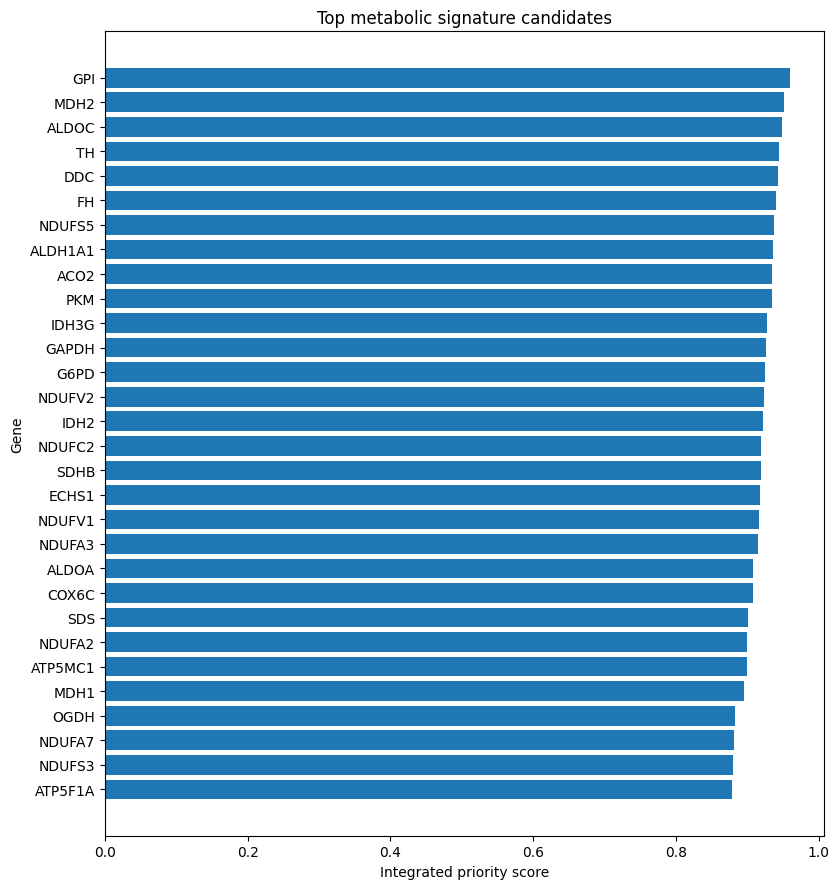

In [16]:
# 15. Top candidate priority plot
top_plot = evidence.head(30).sort_values("priority_score")

fig, ax = plt.subplots(figsize=(8.5, 9))
ax.barh(top_plot["Symbol"], top_plot["priority_score"])
ax.set_xlabel("Integrated priority score")
ax.set_ylabel("Gene")
ax.set_title("Top metabolic signature candidates")
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "GSE136666_SN_top_metabolic_candidate_scores.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

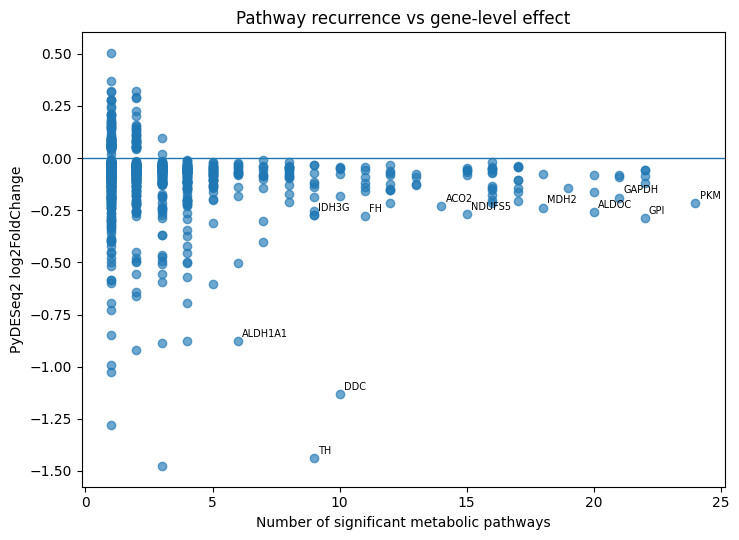

In [17]:
# 16. Pathway recurrence vs gene-level effect
fig, ax = plt.subplots(figsize=(7.5, 5.5))

ax.scatter(
    evidence["metabolic_pathway_count"],
    evidence["log2FoldChange"],
    alpha=0.65,
)

ax.axhline(0, linewidth=1)
ax.set_xlabel("Number of significant metabolic pathways")
ax.set_ylabel("PyDESeq2 log2FoldChange")
ax.set_title("Pathway recurrence vs gene-level effect")

for _, r in evidence.head(12).iterrows():
    ax.annotate(
        r["Symbol"],
        (r["metabolic_pathway_count"], r["log2FoldChange"]),
        fontsize=7,
        xytext=(3, 3),
        textcoords="offset points",
    )

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "GSE136666_SN_pathway_recurrence_vs_log2FC.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

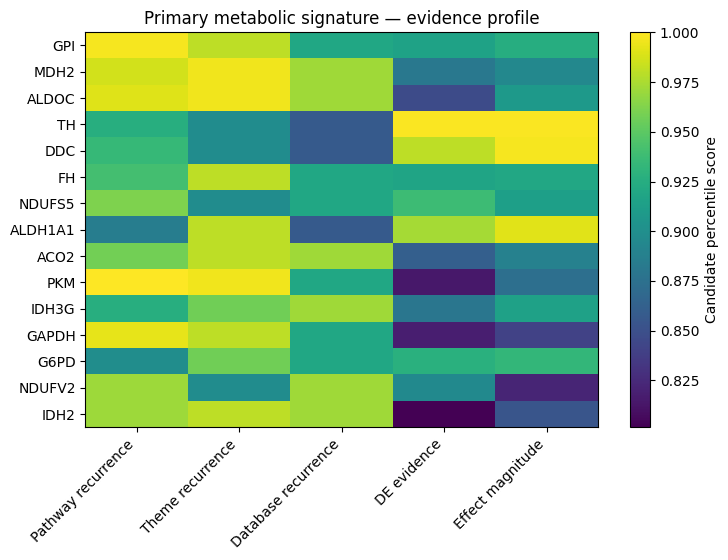

In [18]:
# 17. Primary signature heatmap-style evidence matrix
if len(primary_signature):
    genes = primary_signature["Symbol"].tolist()

    evidence_matrix = pd.DataFrame(index=genes)
    evidence_matrix["Pathway recurrence"] = (
        primary_signature.set_index("Symbol")
        .loc[genes, "score_pathway"]
    )
    evidence_matrix["Theme recurrence"] = (
        primary_signature.set_index("Symbol")
        .loc[genes, "score_theme"]
    )
    evidence_matrix["Database recurrence"] = (
        primary_signature.set_index("Symbol")
        .loc[genes, "score_database"]
    )
    evidence_matrix["DE evidence"] = (
        primary_signature.set_index("Symbol")
        .loc[genes, "score_DE"]
    )
    evidence_matrix["Effect magnitude"] = (
        primary_signature.set_index("Symbol")
        .loc[genes, "score_effect"]
    )

    fig, ax = plt.subplots(
        figsize=(7.5, max(4.5, len(genes) * 0.38))
    )
    im = ax.imshow(evidence_matrix.values, aspect="auto")
    ax.set_xticks(range(evidence_matrix.shape[1]))
    ax.set_xticklabels(
        evidence_matrix.columns,
        rotation=45,
        ha="right"
    )
    ax.set_yticks(range(len(genes)))
    ax.set_yticklabels(genes)
    ax.set_title("Primary metabolic signature — evidence profile")
    fig.colorbar(im, ax=ax, label="Candidate percentile score")
    fig.tight_layout()
    fig.savefig(
        FIGURES_DIR / "GSE136666_SN_primary_signature_evidence_matrix.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()

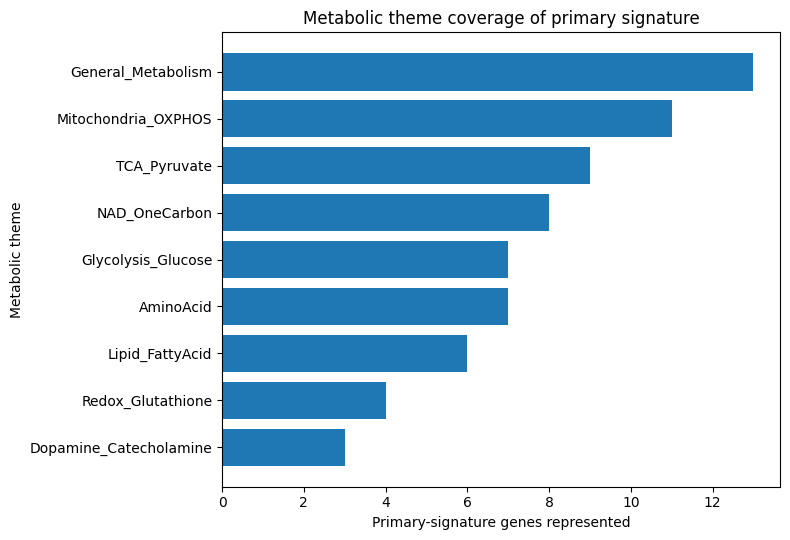

In [19]:
# 18. Metabolic theme representation in the primary signature
primary_theme_counts = pd.Series(dtype=int)

if len(primary_signature):
    primary_gene_set = set(primary_signature["Symbol"])
    primary_theme_counts = (
        gene_theme_long[
            gene_theme_long["Symbol"].isin(primary_gene_set)
        ]
        .groupby("theme")["Symbol"]
        .nunique()
        .sort_values(ascending=True)
    )

    fig, ax = plt.subplots(figsize=(8, 5.5))
    ax.barh(primary_theme_counts.index, primary_theme_counts.values)
    ax.set_xlabel("Primary-signature genes represented")
    ax.set_ylabel("Metabolic theme")
    ax.set_title("Metabolic theme coverage of primary signature")
    fig.tight_layout()
    fig.savefig(
        FIGURES_DIR / "GSE136666_SN_primary_signature_theme_coverage.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()

# Part G — Internal robustness checks

These checks are descriptive, not independent validation.

We ask:
- Does the primary signature contain both pathway recurrence and DE evidence?
- Does it cover more than one metabolic theme?
- Are directions explicit?
- Are pathway-driver genes distinguishable from individually significant DEGs?

True validation will occur later using the independent GSE184950 cohort.

In [20]:
# 19. Primary signature robustness summary
robustness = pd.Series({
    "primary_genes": len(primary_signature),
    "DE_FDR_genes": int(primary_signature["DE_FDR"].sum()),
    "pathway_driver_or_higher": int(
        primary_signature["evidence_tier"]
        .isin(["A_Integrated_high_confidence", "B_Pathway_driver"])
        .sum()
    ),
    "direction_concordant_genes": int(
        primary_signature["Direction_concordant"].sum()
    ),
    "unique_metabolic_themes": int(
        gene_theme_long[
            gene_theme_long["Symbol"].isin(primary_signature["Symbol"])
        ]["theme"].nunique()
    ),
    "unique_pathway_databases": int(
        gene_pathway_long[
            gene_pathway_long["Symbol"].isin(primary_signature["Symbol"])
        ]["library_family"].nunique()
    ),
    "up_in_Parkinson": int(
        (primary_signature["log2FoldChange"] > 0).sum()
    ),
    "down_in_Parkinson": int(
        (primary_signature["log2FoldChange"] < 0).sum()
    ),
})

display(robustness)

primary_genes                 15
DE_FDR_genes                   3
pathway_driver_or_higher      15
direction_concordant_genes    15
unique_metabolic_themes        9
unique_pathway_databases       5
up_in_Parkinson                0
down_in_Parkinson             15
dtype: int64

# Part H — Exports for downstream notebooks

The most important outputs are:

### For Notebook 07/08
- `primary_metabolic_signature.csv`
- `extended_metabolic_validation_signature.csv`
- expected bulk direction for each gene.

### For Notebook 09
- full prioritized metabolic candidate table;
- gene-theme relationships;
- pathway representatives.

### For Notebook 10/11
Only after independent validation:
- a reduced subset of these features may be considered for exploratory ML/XAI.

In [21]:
# 20. Export all signature products
evidence.to_csv(
    EXPORT_DIR / "GSE136666_SN_metabolic_candidates_prioritized.csv",
    index=False,
)

primary_signature.to_csv(
    EXPORT_DIR / "GSE136666_SN_primary_metabolic_signature.csv",
    index=False,
)

extended_signature.to_csv(
    EXPORT_DIR / "GSE136666_SN_extended_metabolic_validation_signature.csv",
    index=False,
)

gene_pathway_long.to_csv(
    RESULTS_DIR / "GSE136666_SN_gene_pathway_evidence_long.csv",
    index=False,
)

gene_theme_long.to_csv(
    RESULTS_DIR / "GSE136666_SN_gene_theme_evidence_long.csv",
    index=False,
)

gene_theme_matrix.to_csv(
    RESULTS_DIR / "GSE136666_SN_gene_theme_matrix.csv",
)

gene_database_matrix.to_csv(
    RESULTS_DIR / "GSE136666_SN_gene_database_matrix.csv",
)

pathway_signature.to_csv(
    EXPORT_DIR / "GSE136666_SN_metabolic_pathway_signature.csv",
    index=False,
)

tier_summary.to_csv(
    RESULTS_DIR / "GSE136666_SN_signature_tier_summary.csv",
    index=False,
)

tier_metrics.to_csv(
    RESULTS_DIR / "GSE136666_SN_signature_tier_metrics.csv",
    index=False,
)

if len(primary_theme_counts):
    primary_theme_counts.rename("gene_count").to_csv(
        RESULTS_DIR / "GSE136666_SN_primary_signature_theme_coverage.csv"
    )

print("Exports:", EXPORT_DIR.resolve())
print("Results:", RESULTS_DIR.resolve())
print("Figures:", FIGURES_DIR.resolve())

Exports: /mnt/data/data/processed/notebook05
Results: /mnt/data/results/metabolic_signatures
Figures: /mnt/data/figures/metabolic_signatures


In [22]:
# 21. Reproducibility manifest
manifest05 = {
    "dataset": "GSE136666",
    "tissue": "Substantia nigra",
    "contrast": "Parkinson vs Control",
    "source": "Notebook 04 formal PyDESeq2-derived metabolic GSEA outputs",
    "alpha": ALPHA,
    "pathway_recurrence_high_threshold": float(q75_pathways),
    "primary_signature_max_genes": PRIMARY_MAX_GENES,
    "extended_signature_max_genes": EXTENDED_MAX_GENES,
    "priority_score_weights": {
        "pathway_recurrence": 0.35,
        "theme_recurrence": 0.15,
        "database_recurrence": 0.10,
        "gene_level_FDR": 0.20,
        "absolute_log2FC": 0.15,
        "direction_concordance": 0.05,
    },
    "primary_signature_genes": primary_signature["Symbol"].tolist(),
    "extended_signature_genes": extended_signature["Symbol"].tolist(),
    "next_validation_dataset": "GSE184950",
    "next_relevant_notebooks": [
        "06_single_nucleus_preprocessing.ipynb",
        "07_cell_type_PD_analysis.ipynb",
        "08_cross_dataset_validation.ipynb",
    ],
}

with open(
    EXPORT_DIR / "notebook05_manifest.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(manifest05, f, indent=2, ensure_ascii=False)

print(json.dumps(manifest05, indent=2, ensure_ascii=False))

{
  "dataset": "GSE136666",
  "tissue": "Substantia nigra",
  "contrast": "Parkinson vs Control",
  "source": "Notebook 04 formal PyDESeq2-derived metabolic GSEA outputs",
  "alpha": 0.05,
  "pathway_recurrence_high_threshold": 4.0,
  "primary_signature_max_genes": 15,
  "extended_signature_max_genes": 40,
  "priority_score_weights": {
    "pathway_recurrence": 0.35,
    "theme_recurrence": 0.15,
    "database_recurrence": 0.1,
    "gene_level_FDR": 0.2,
    "absolute_log2FC": 0.15,
    "direction_concordance": 0.05
  },
  "primary_signature_genes": [
    "GPI",
    "MDH2",
    "ALDOC",
    "TH",
    "DDC",
    "FH",
    "NDUFS5",
    "ALDH1A1",
    "ACO2",
    "PKM",
    "IDH3G",
    "GAPDH",
    "G6PD",
    "NDUFV2",
    "IDH2"
  ],
  "extended_signature_genes": [
    "GPI",
    "MDH2",
    "ALDOC",
    "TH",
    "DDC",
    "FH",
    "NDUFS5",
    "ALDH1A1",
    "ACO2",
    "PKM",
    "IDH3G",
    "GAPDH",
    "G6PD",
    "NDUFV2",
    "IDH2",
    "NDUFC2",
    "SDHB",
    "ECHS1",
 

In [23]:
# 22. Final checkpoint
checks = pd.Series({
    "Significant metabolic pathways loaded": len(gsea) > 0,
    "Leading-edge candidates loaded": len(candidates) > 0,
    "Gene-pathway evidence reconstructed": len(gene_pathway_long) > 0,
    "Gene-theme evidence reconstructed": len(gene_theme_long) > 0,
    "Prioritized candidate table created": len(evidence) > 0,
    "Primary signature non-empty": len(primary_signature) > 0,
    "Extended signature non-empty": len(extended_signature) > 0,
    "Expected directions assigned": (
        primary_signature["expected_bulk_direction"].notna().all()
    ),
})

display(checks)

assert checks.all(), "Notebook 05 checkpoint failed."

print("\n✓ Notebook 05 completed successfully.")
print("Primary signature genes:")
print(", ".join(primary_signature["Symbol"].tolist()))
print(
    "\nThese are discovery candidates, not yet independently validated."
)
print(
    "The next biological validation step is GSE184950 "
    "single-nucleus preprocessing and donor-level pseudobulk."
)

Significant metabolic pathways loaded    True
Leading-edge candidates loaded           True
Gene-pathway evidence reconstructed      True
Gene-theme evidence reconstructed        True
Prioritized candidate table created      True
Primary signature non-empty              True
Extended signature non-empty             True
Expected directions assigned             True
dtype: bool


✓ Notebook 05 completed successfully.
Primary signature genes:
GPI, MDH2, ALDOC, TH, DDC, FH, NDUFS5, ALDH1A1, ACO2, PKM, IDH3G, GAPDH, G6PD, NDUFV2, IDH2

These are discovery candidates, not yet independently validated.
The next biological validation step is GSE184950 single-nucleus preprocessing and donor-level pseudobulk.


# Thesis interpretation guide

A safe Results statement after this notebook is:

> Significant metabolism-associated gene sets were decomposed into their leading-edge genes and integrated with gene-level differential-expression statistics. Candidate genes were prioritized using pathway recurrence, metabolic-theme recurrence, pathway-database recurrence, gene-level false-discovery-rate evidence, effect size and concordance between gene-level and pathway-level direction. This yielded a compact discovery signature and an extended validation set for subsequent evaluation in an independent single-nucleus RNA-sequencing cohort.

Do **not** yet write:

> “These genes are validated Parkinson biomarkers.”

They are still **discovery-stage candidates**.

Independent support will be sought in GSE184950 at donor and cell-type resolution.